<a href="https://colab.research.google.com/github/Lee-hosuk/game-agent/blob/main/frozenlake/frozenlake.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧊 FrozenLake - Q-러닝 직접 구현

얼음판 위에서 구멍(H)을 피해 시작점(S)에서 선물(G)까지 가는 게임입니다.
이번에는 PPO 같은 라이브러리 없이 **Q-러닝 알고리즘을 직접** 짜서 학습시킵니다.

```
S F F F      S: 시작   F: 얼음(안전)
F H F H      H: 구멍(빠지면 실패)
F F F H      G: 선물(도착하면 성공, 보상 +1)
H F F G
```

## 1. 설치

In [1]:
!pip install "gymnasium[toy-text]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 46.1 MB/s  0:00:00


## 2. 환경 살펴보기
- **obs**: 지금 서 있는 칸 번호 하나 (0~15). 왼쪽 위가 0, 오른쪽 아래가 15
- **행동**: 0=왼쪽, 1=아래, 2=오른쪽, 3=위
- **보상**: 선물(G)에 도착하면 +1, 나머지는 전부 0

In [2]:
import gymnasium as gym
import numpy as np

# is_slippery=False: 미끄러지지 않음 (누른 방향으로 정확히 이동)
env = gym.make("FrozenLake-v1", is_slippery=False)

n_states = env.observation_space.n    # 칸 개수: 16
n_actions = env.action_space.n        # 행동 개수: 4
print("칸 개수:", n_states, "/ 행동 개수:", n_actions)

obs, _ = env.reset(seed=0)
print("시작 위치:", obs)
obs, reward, done, truncated, _ = env.step(2)   # 오른쪽으로 한 칸
print("오른쪽으로 이동 후 위치:", obs, "/ 보상:", reward)

칸 개수: 16 / 행동 개수: 4
시작 위치: 0
오른쪽으로 이동 후 위치: 1 / 보상: 0


## 3. Q-테이블 만들기

**Q-테이블**은 "이 칸에서 이 행동을 하면 앞으로 얼마나 좋을까?"를 적어두는 점수표입니다.
16칸 × 4행동 = 64개의 점수가 있고, 처음엔 전부 0입니다.

In [3]:
Q = np.zeros((n_states, n_actions))
print(Q.shape)
print(Q[:4])   # 0~3번 칸의 점수 (아직 전부 0)

(16, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


## 4. 학습 설정
- **alpha (학습률)**: 새로 경험한 걸 얼마나 크게 반영할지 (0~1)
- **gamma (할인율)**: 미래의 보상을 얼마나 중요하게 볼지 (0~1). 1에 가까울수록 멀리 내다봄
- **epsilon (탐험 확률)**: 아는 최선 대신 랜덤으로 행동해볼 확률. 처음엔 1(전부 랜덤)에서 시작해 점점 줄임

In [4]:
alpha = 0.8
gamma = 0.95
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995   # 한 판 끝날 때마다 epsilon에 곱함
episodes = 2000         # 총 2000판 플레이

def best_action(Q, state):
    """점수가 가장 높은 행동을 고름. 동점이면 그중 랜덤으로 고름"""
    q = Q[state]
    return np.random.choice(np.flatnonzero(q == q.max()))

## 5. Q-러닝 학습 ⭐ (핵심)

매 스텝마다 Q-테이블을 이렇게 고칩니다.

```
Q[칸, 행동] ← Q[칸, 행동] + alpha × (보상 + gamma × 다음 칸의 최고 점수 − Q[칸, 행동])
```
"내가 예상한 점수"와 "실제로 해보니 나온 점수"의 차이만큼 조금씩 고쳐 나가는 방식입니다.

In [5]:
rng = np.random.default_rng(0)
np.random.seed(0)
rewards = []    # 판마다 성공(1)/실패(0) 기록

for ep in range(episodes):
    state, _ = env.reset()
    done = truncated = False

    while not (done or truncated):
        # 1) 행동 고르기: epsilon 확률로 탐험(랜덤), 아니면 아는 최선
        if rng.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = best_action(Q, state)

        # 2) 행동하고 결과 받기
        next_state, reward, done, truncated, _ = env.step(action)

        # 3) Q-테이블 업데이트
        future = 0 if done else np.max(Q[next_state])   # 끝난 칸에는 미래가 없음
        target = reward + gamma * future
        Q[state, action] += alpha * (target - Q[state, action])

        state = next_state

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards.append(reward)

    if (ep + 1) % 200 == 0:
        rate = np.mean(rewards[-200:]) * 100
        print(f"{ep+1:5d}판 | 최근 200판 성공률 {rate:5.1f}% | epsilon {epsilon:.3f}")

  200판 | 최근 200판 성공률   0.5% | epsilon 0.367
  400판 | 최근 200판 성공률  59.0% | epsilon 0.135
  600판 | 최근 200판 성공률  92.0% | epsilon 0.049
  800판 | 최근 200판 성공률  97.0% | epsilon 0.018
 1000판 | 최근 200판 성공률  98.5% | epsilon 0.010
 1200판 | 최근 200판 성공률 100.0% | epsilon 0.010
 1400판 | 최근 200판 성공률  99.5% | epsilon 0.010
 1600판 | 최근 200판 성공률  99.5% | epsilon 0.010
 1800판 | 최근 200판 성공률  97.0% | epsilon 0.010
 2000판 | 최근 200판 성공률  99.5% | epsilon 0.010


## 6. 학습 곡선

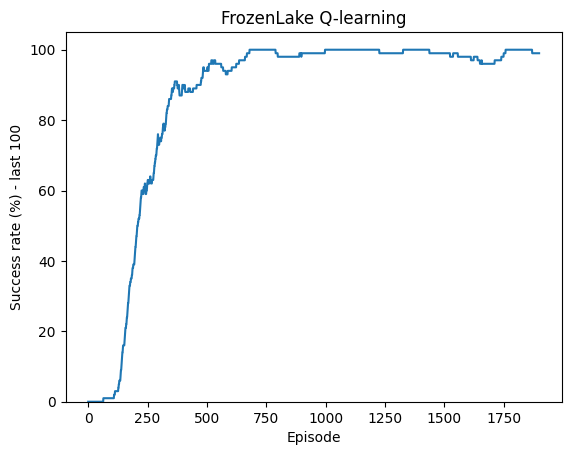

In [6]:
import matplotlib.pyplot as plt

window = 100
moving = np.convolve(rewards, np.ones(window) / window, mode="valid") * 100
plt.plot(moving)
plt.xlabel("Episode")
plt.ylabel("Success rate (%) - last 100")
plt.title("FrozenLake Q-learning")
plt.ylim(0, 105)
plt.show()

## 7. 학습된 Q-테이블 들여다보기
PPO의 신경망과 달리 Q-러닝은 **배운 내용을 표로 직접 볼 수 있다**는 게 장점입니다.

In [7]:
np.set_printoptions(precision=2, suppress=True)
print("칸 |  왼쪽   아래  오른쪽   위")
for s in range(n_states):
    print(f"{s:2d} | {Q[s]}")

# 칸마다 가장 점수가 높은 방향을 화살표로 표시
arrows = ["←", "↓", "→", "↑"]
desc = env.unwrapped.desc.astype(str)
print("\n학습된 정책 (H=구멍, G=선물)")
for r in range(4):
    row = ""
    for c in range(4):
        s = r * 4 + c
        cell = desc[r, c]
        row += f" {cell} " if cell in "HG" else f" {arrows[int(np.argmax(Q[s]))]} "
    print(row)

칸 |  왼쪽   아래  오른쪽   위
 0 | [0.74 0.77 0.7  0.74]
 1 | [0.74 0.   0.   0.  ]
 2 | [0.7  0.49 0.   0.  ]
 3 | [0. 0. 0. 0.]
 4 | [0.77 0.81 0.   0.74]
 5 | [0. 0. 0. 0.]
 6 | [0.   0.   0.   0.66]
 7 | [0. 0. 0. 0.]
 8 | [0.81 0.   0.86 0.77]
 9 | [0.81 0.9  0.9  0.  ]
10 | [0.86 0.95 0.   0.63]
11 | [0. 0. 0. 0.]
12 | [0. 0. 0. 0.]
13 | [0.   0.72 0.95 0.86]
14 | [0.9  0.95 1.   0.9 ]
15 | [0. 0. 0. 0.]

학습된 정책 (H=구멍, G=선물)
 ↓  ←  ←  ← 
 ↓  H  ↑  H 
 →  →  ↓  H 
 H  →  →  G 


## 8. 학습 전 vs 학습 후 GIF
학습 전은 아무것도 모르니 랜덤으로 움직이는 에이전트, 학습 후는 Q-테이블의 최선만 따르는 에이전트입니다.

학습 전: 11스텝, 실패 🕳️
학습 후: 6스텝, 성공 🎁


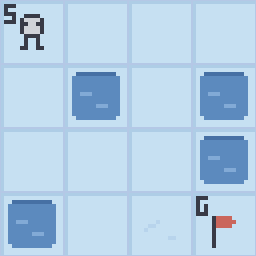

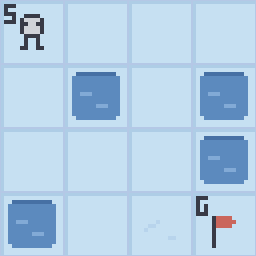

In [8]:
import imageio
from IPython.display import Image, display

def record(policy, filename, seed=0, max_steps=50):
    env = gym.make("FrozenLake-v1", is_slippery=False, render_mode="rgb_array")
    state, _ = env.reset(seed=seed)
    env.action_space.seed(seed)
    frames, steps, reward = [env.render()], 0, 0
    for _ in range(max_steps):
        action = policy(env, state)
        state, reward, done, truncated, _ = env.step(action)
        frames.append(env.render())
        steps += 1
        if done or truncated:
            break
    frames += [frames[-1]] * 5    # 마지막 장면을 잠깐 멈춰서 보여줌
    imageio.mimsave(filename, frames, duration=0.4)
    return steps, reward

random_policy = lambda env, s: env.action_space.sample()
trained_policy = lambda env, s: int(np.argmax(Q[s]))

b_steps, b_reward = record(random_policy, "frozenlake_untrained.gif")
a_steps, a_reward = record(trained_policy, "frozenlake_trained.gif")

result = lambda r: "성공 🎁" if r == 1 else "실패 🕳️"
print(f"학습 전: {b_steps}스텝, {result(b_reward)}")
print(f"학습 후: {a_steps}스텝, {result(a_reward)}")
display(Image(open("frozenlake_untrained.gif", "rb").read()))
display(Image(open("frozenlake_trained.gif", "rb").read()))

## 9. 성공률로 공정하게 비교하기
GIF는 한 판뿐이라 운이 섞입니다. 100판씩 돌려서 성공률을 비교해봅니다.

In [9]:
def success_rate(policy, n=100):
    env = gym.make("FrozenLake-v1", is_slippery=False)
    env.action_space.seed(0)
    wins = 0
    for i in range(n):
        state, _ = env.reset(seed=i)
        done = truncated = False
        while not (done or truncated):
            state, reward, done, truncated, _ = env.step(policy(env, state))
        wins += reward
    return wins / n * 100

print(f"학습 전(랜덤) 성공률: {success_rate(random_policy):.0f}%")
print(f"학습 후 성공률:      {success_rate(trained_policy):.0f}%")

학습 전(랜덤) 성공률: 0%
학습 후 성공률:      100%


## 🔥 도전 과제
1. 2번 셀에서 `is_slippery=True`로 바꿔보세요. 얼음이 미끄러워서 누른 방향과 다르게 움직일 수 있습니다. (8, 9번 셀의 `is_slippery`도 같이 바꾸기)
   - 성공률이 확 떨어집니다. `alpha`를 0.1로 낮추고 `episodes`를 10000으로 늘려보세요.
2. `gamma`를 0.5로 낮추면 어떻게 될까요? 학습된 정책 화살표가 어떻게 바뀌는지 보세요.
3. `epsilon_decay`를 0.9로 바꿔서 탐험을 빨리 끝내면 학습이 잘 될까요?
4. `map_name="8x8"`을 추가해서 더 큰 지도에 도전해보세요.